In [74]:
import torch
import numpy as np

In [75]:
text1 = "aaaaaaaabcddacacadad"
ids = list(text.encode("utf-8"))
# ids是[97, 97, 97, 98]，对应字符的utf-8 byte编码
# 当你遍历 bytes 时，
# 取出来的每个元素会被表示成一个 0~255 的整数
ids

[104, 101, 108, 108, 111, 100, 97, 110, 97, 98, 104, 101, 108, 108]

In [80]:
# zip() 函数可以将两个可迭代对象打包成一个元组列表
def get_stats(ids):
    """
    统计相邻 token pair 出现的次数
    """
    counts = {}

    for pair in zip(ids, ids[1:]):
        #[1,2,3,4] [2,3,4]
        # 这里想象成一个滑动窗口，窗口大小为2，滑动步长为1
        # 结果是[(1,2),(2,3),(3,4)]
        # get() 方法返回指定键的值，
        # 如果键不在字典中返回默认值0。
        # pair是元组对象
        counts[pair] = counts.get(pair, 0) + 1

    return counts


get_stats(ids)

{(104, 101): 2,
 (101, 108): 2,
 (108, 108): 2,
 (108, 111): 1,
 (111, 100): 1,
 (100, 97): 1,
 (97, 110): 1,
 (110, 97): 1,
 (97, 98): 1,
 (98, 104): 1}

In [ ]:
#ids 序列
# pair 是一个元组，表示要合并的两个 token
# idx 是合并后的新 token 的索引 从256开始
# 因为前面的utf-8编码0-255 已被占据
def merge(ids, pair, idx=256):
    """
    把 ids 中所有连续出现的 pair 合并成新的 token idx
    """
    newids = []
    i = 0

    while i < len(ids):
        if (
            i < len(ids) - 1
            and ids[i] == pair[0]
            and ids[i + 1] == pair[1]
        ):
            newids.append(idx)
            i += 2
        else:
            newids.append(ids[i])
            i += 1

    return newids
# 可以看见已经被修改
print("ids before merge:", ids)
newids1 = merge(ids, (108, 108), 256) 
print("ids after merge:", newids1)  

ids before merge: [104, 101, 108, 108, 111, 100, 97, 110, 97, 98, 104, 101, 108, 108]
ids after merge: [104, 101, 256, 111, 100, 97, 110, 97, 98, 104, 101, 256]


In [86]:
text = """
banana bandana banana banana
banana bandana banana bandana
machine learning learning machine
token token tokenizer token token
abababababab abcabcabcabc
hello hello hello world world
"""

In [87]:
token = text.encode("utf-8")
vocab_size = 276 # destination vocab size
num_merges = vocab_size - 256 # 256是utf-8编码的数量
# ids输入序列的token化表示
ids = list(token)
print(f"initial ids length: {len(ids)}")
merges = {} #(int,int) -> int
for i in range(num_merges):
    counts = get_stats(ids)
    if not counts:
        break
    pair = max(counts, key=counts.get)
    idx = 256 + i
    print(f"merging{pair} into a new token{idx}")
    ids = merge(ids, pair, idx)
    merges[pair] = idx

initial ids length: 184
merging(97, 110) into a new token256
merging(97, 98) into a new token257
merging(98, 256) into a new token258
merging(256, 97) into a new token259
merging(259, 32) into a new token260
merging(260, 258) into a new token261
merging(116, 111) into a new token262
merging(262, 107) into a new token263
merging(263, 101) into a new token264
merging(264, 110) into a new token265
merging(257, 257) into a new token266
merging(105, 110) into a new token267
merging(32, 265) into a new token268
merging(257, 99) into a new token269
merging(261, 100) into a new token270
merging(269, 269) into a new token271
merging(104, 101) into a new token272
merging(272, 108) into a new token273
merging(273, 108) into a new token274
merging(274, 111) into a new token275


In [88]:
len(ids)

78

In [90]:
# 评价指标
# 添加词汇越多压缩比越大
print(f"tokens length1: {len(token)}")
print("ids length: ",len(ids))
print(f"compression ratio: {len(token)/len(ids):.2f}")

tokens length1: 184
ids length:  78
compression ratio: 2.36


![llm okenizer.png](<attachment:llm okenizer.png>)
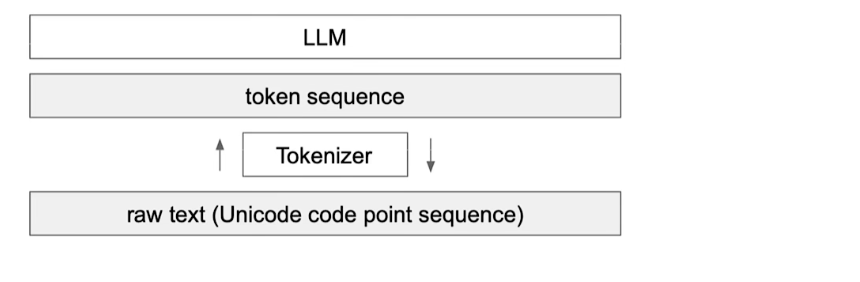

In [91]:
# 记住我们前面实现的 merges{}
# 里面存储了所有的合并操作
# 在解码的过程我们需要使用它们来还原原始的 token 序列

In [92]:
vocab = {idx: bytes([idx]) for idx in range(256)}
vocab

{0: b'\x00',
 1: b'\x01',
 2: b'\x02',
 3: b'\x03',
 4: b'\x04',
 5: b'\x05',
 6: b'\x06',
 7: b'\x07',
 8: b'\x08',
 9: b'\t',
 10: b'\n',
 11: b'\x0b',
 12: b'\x0c',
 13: b'\r',
 14: b'\x0e',
 15: b'\x0f',
 16: b'\x10',
 17: b'\x11',
 18: b'\x12',
 19: b'\x13',
 20: b'\x14',
 21: b'\x15',
 22: b'\x16',
 23: b'\x17',
 24: b'\x18',
 25: b'\x19',
 26: b'\x1a',
 27: b'\x1b',
 28: b'\x1c',
 29: b'\x1d',
 30: b'\x1e',
 31: b'\x1f',
 32: b' ',
 33: b'!',
 34: b'"',
 35: b'#',
 36: b'$',
 37: b'%',
 38: b'&',
 39: b"'",
 40: b'(',
 41: b')',
 42: b'*',
 43: b'+',
 44: b',',
 45: b'-',
 46: b'.',
 47: b'/',
 48: b'0',
 49: b'1',
 50: b'2',
 51: b'3',
 52: b'4',
 53: b'5',
 54: b'6',
 55: b'7',
 56: b'8',
 57: b'9',
 58: b':',
 59: b';',
 60: b'<',
 61: b'=',
 62: b'>',
 63: b'?',
 64: b'@',
 65: b'A',
 66: b'B',
 67: b'C',
 68: b'D',
 69: b'E',
 70: b'F',
 71: b'G',
 72: b'H',
 73: b'I',
 74: b'J',
 75: b'K',
 76: b'L',
 77: b'M',
 78: b'N',
 79: b'O',
 80: b'P',
 81: b'Q',
 82: b'R',
 83: b'

In [93]:
merges
# 注意观察 我们byte解码的范围 0-255
# merges 要拆分开再次分解到 0- 255 范围内

{(97, 110): 256,
 (97, 98): 257,
 (98, 256): 258,
 (256, 97): 259,
 (259, 32): 260,
 (260, 258): 261,
 (116, 111): 262,
 (262, 107): 263,
 (263, 101): 264,
 (264, 110): 265,
 (257, 257): 266,
 (105, 110): 267,
 (32, 265): 268,
 (257, 99): 269,
 (261, 100): 270,
 (269, 269): 271,
 (104, 101): 272,
 (272, 108): 273,
 (273, 108): 274,
 (274, 111): 275}

In [94]:
for (p0, p1), idx in merges.items():
    vocab[idx] = vocab[p0] + vocab[p1]


In [95]:
print(vocab[97])
print(vocab[256])
print(vocab[257])
print(vocab[274])

b'a'
b'an'
b'ab'
b'hell'


**相当于给0-255的容量作了一个扩充**，
       

In [67]:
#  hell
# he   ll
#h e   l l

In [96]:
def decode(ids):
    tokens = b"".join(vocab[idx] for idx in ids)
    text = tokens.decode("utf-8", errors="replace")
    return text

In [97]:
ids = [104, 101, 108, 108, 111, 100, 256, 257, 274]

text = decode(ids)

print(text)

hellodanabhell


In [98]:
merges

{(97, 110): 256,
 (97, 98): 257,
 (98, 256): 258,
 (256, 97): 259,
 (259, 32): 260,
 (260, 258): 261,
 (116, 111): 262,
 (262, 107): 263,
 (263, 101): 264,
 (264, 110): 265,
 (257, 257): 266,
 (105, 110): 267,
 (32, 265): 268,
 (257, 99): 269,
 (261, 100): 270,
 (269, 269): 271,
 (104, 101): 272,
 (272, 108): 273,
 (273, 108): 274,
 (274, 111): 275}

In [99]:
text2 = "pppaaaahellhl"

In [ ]:
def encode(text):
    # string - > byte almost 一对一的 
    tokens = list(text.encode("utf-8"))
    while len(tokens) > 1: 
        stats = get_stats(tokens)
        # key=lambda p: merges.get(p, float("inf")) 这个参数的意思是
        # 对于每一个相邻的 token pair p，查找它在 merges 字典中的值
        # 如果找不到就返回无穷大（float("inf")）。
        pair = min(stats, key = lambda p: merges.get(p, float("inf")))
        if pair not in merges:
            break
        # merges is like = {(245,125):256}
        # 取出我们的 pair 对应的合并后的新 token 的索引
        # tips： merges 是我们使用bpe在一些文本中 训练好的
        # 只是说我们输入新文本 需要使用它来进行编码
        idx = merges[pair]
        tokens = merge(tokens, pair, idx)
    return tokens
tx2_ids = encode(text2)
tx2_ids
# 注意 超过255的token是我们训练好的bpe词汇表中的新词汇

[112, 112, 112, 97, 97, 97, 97, 274, 104, 108]

In [104]:
# 对于新文本的解码 要满足验证 一致性
print(decode(encode("hello world")))

hello world


**Modern Tokenizer(Like GPT Series)**

我们发现在训练tokenizer时 我们尝试不去合并字母、数字和标点符号等.

In [112]:
import regex as re

gpt2pat = re.compile(
    r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+"""
)
# gpt2 like space
print(re.findall(gpt2pat, "Hello've world123 how's are       you!!!!?    "))

['Hello', "'ve", ' world', '123', ' how', "'s", ' are', '      ', ' you', '!!!!?', '    ']


In [115]:
example = """
for i in range(1, 101):
    if i % 3 == 0 and i % 5 == 0:
        print("FizzBuzz")
    elif i % 3 == 0:
        print("Fizz")
    elif i % 5 == 0:
        print("Buzz")
    else:
        print(i)
"""
print(re.findall(gpt2pat, example))

['\n', 'for', ' i', ' in', ' range', '(', '1', ',', ' 101', '):', '\n   ', ' if', ' i', ' %', ' 3', ' ==', ' 0', ' and', ' i', ' %', ' 5', ' ==', ' 0', ':', '\n       ', ' print', '("', 'FizzBuzz', '")', '\n   ', ' elif', ' i', ' %', ' 3', ' ==', ' 0', ':', '\n       ', ' print', '("', 'Fizz', '")', '\n   ', ' elif', ' i', ' %', ' 5', ' ==', ' 0', ':', '\n       ', ' print', '("', 'Buzz', '")', '\n   ', ' else', ':', '\n       ', ' print', '(', 'i', ')', '\n']


**即使gpt4中间也保存了一个merges代表合并的词元组，以及对应的vocab**
类似于 merges = {(90,190):256} 
, vocab = {'a', .....'hl'}